In [1]:
%matplotlib inline

## All Attacks

In [3]:
from numbers import Integral

import numpy as np
import secrets

from modules import *

In [4]:
def run(attack, signal_channel=None, sifted_key_index=0, seed=secrets.randbits(128)):
    bb84 = BB84(seed=seed, number_bits=48)
    sifted_indices = [i for i, match in enumerate(bb84.alice_bases == bb84.bob_bases) if match]
    round_index = sifted_indices[sifted_key_index]
    
    alice, bob = bb84.key_generation(attack=attack, signal_channel=signal_channel, record_rounds=[round_index])

    print("Alice's sifted key:", "".join(map(str, alice)))
    print("Bob's sifted key:  ", "".join(map(str, bob)))
    
    if attack is not None:
        guesses = bb84.eve_guesses()
        print("Eve's guesses:     ", "".join(map(str, guesses)))
    print(f"QBER: {sum(alice != bob)}/{len(alice)} = {bb84.qber():.1%}")

    basis = bb84.alice_bases[round_index]
    bb84.display(round_index=round_index, title=f"Sifted Key Index {sifted_key_index} | Alice & Bob Basis: {basis}")

Alice's sifted key: 100101011010000100011111111
Bob's sifted key:   100101011010000100011111111
QBER: 0/27 = 0.0%


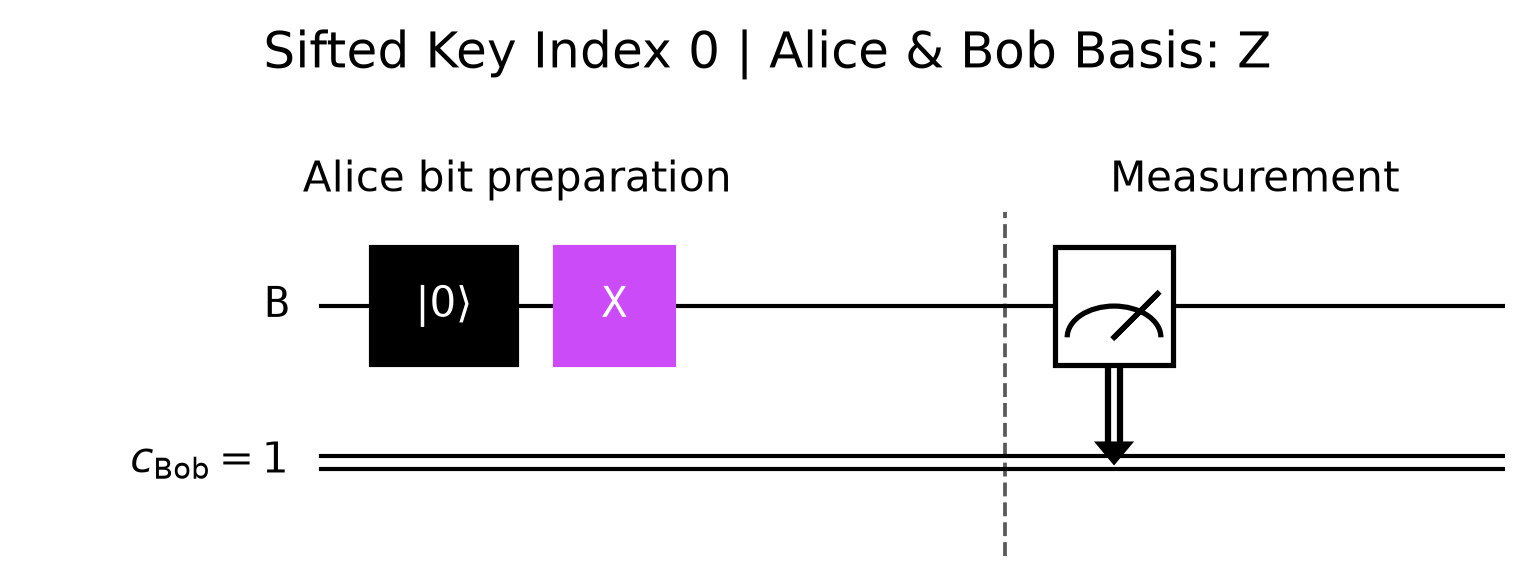

In [5]:
run(attack=None)

Alice's sifted key: 100101011010000100011111111
Bob's sifted key:   000001111001111000111001101
Eve's guesses:      000101111010001000011011101
QBER: 13/27 = 48.1%


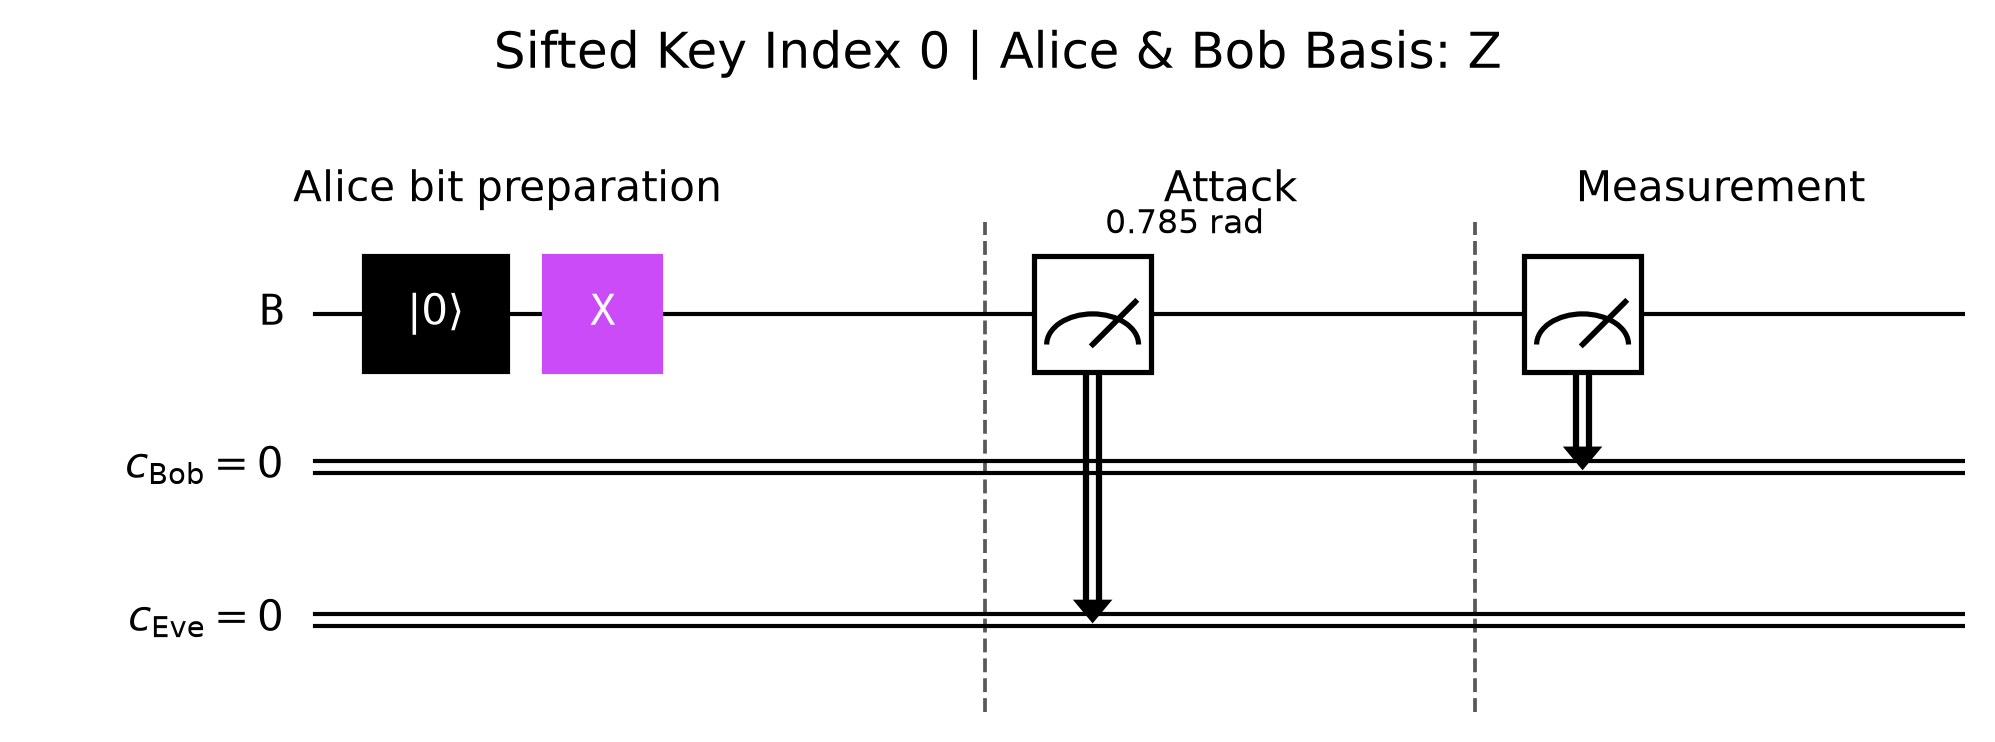

In [6]:
run(attack=BreidbartAttack())